In [ ]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scikit_posthocs as sp

from scipy.stats import friedmanchisquare
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

In [2]:
import glob, os

os.makedirs('results', exist_ok=True)

result_files = [
    p for p in glob.glob("results/*_results.csv")
    if os.path.basename(p) != "all_results.csv"
]

frames = []

for path in result_files:
    d = pd.read_csv(path)

    parts = d["Model"].str.split(
        "+",
        n=1,
        expand=True
    )

    d["fs_method"] = parts[0].str.strip()
    d["classifier"] = parts[1].str.strip()

    frames.append(d)

all_results = pd.concat(frames, ignore_index=True)

# normalize classifier names so they match exactly across FS scripts
name_map = {
    'Logistic Regression': 'LR',
    'Random Forest': 'RF',
    'XGBoost': 'XGB',
    'CatBoost': 'CAT',
    'lightgbm': 'LGBM',
    'MLP': 'MLP'
}
all_results['classifier'] = all_results['classifier'].replace(name_map)

# reorder so the key columns lead
lead = ['fs_method', 'classifier', 'ROC_AUC' , 'MCC', 'PR_AUC']
cols = lead + [c for c in all_results.columns if c not in lead + ['Model']]
all_results = all_results[cols]

all_results.to_csv('results/all_results.csv', index=False)


In [3]:
print(f"{len(all_results)} rows  (expect 48)")
print("FS methods :", sorted(all_results.fs_method.unique()))
print("Classifiers:", sorted(all_results.classifier.unique()))

pivot = all_results.pivot_table(index='fs_method', columns='classifier',
                                values='PR_AUC', aggfunc='count')
print(pivot.fillna(0).astype(int))

48 rows  (expect 48)
FS methods : ['GA', 'GWO', 'Lasso', 'MI', 'NO FS', 'PSO', 'RFE', 'RFI']
Classifiers: ['CAT', 'LGBM', 'LR', 'MLP', 'RF', 'XGB']
classifier  CAT  LGBM  LR  MLP  RF  XGB
fs_method                              
GA            1     1   1    1   1    1
GWO           1     1   1    1   1    1
Lasso         1     1   1    1   1    1
MI            1     1   1    1   1    1
NO FS         1     1   1    1   1    1
PSO           1     1   1    1   1    1
RFE           1     1   1    1   1    1
RFI           1     1   1    1   1    1


In [ ]:
# 1. SETTINGS
# ============================================================

PRIMARY_METRIC = "PR_AUC"
ALPHA = 0.05

OUTPUT_DIR = "statistical_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Optional preferred ordering
FS_ORDER = ["NO FS", "MI", "Lasso", "RFI", "RFE", "GA", "PSO","GWO"]
CLASSIFIER_ORDER = ["LR", "RF", "XGB", "CAT","LGBM","MLP"]


In [5]:
# 2. LOAD AND VALIDATE DATA
# ============================================================

df = pd.read_csv("results/all_results.csv")

required_columns = {
    "fs_method",
    "classifier",
    PRIMARY_METRIC
}

missing_columns = required_columns.difference(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

df[PRIMARY_METRIC] = pd.to_numeric(
    df[PRIMARY_METRIC],
    errors="coerce"
)

if df[PRIMARY_METRIC].isna().any():
    raise ValueError(
        f"{PRIMARY_METRIC} contains missing or non-numeric values."
    )

print("Dataset shape:", df.shape)
print("\nFeature-selection methods:")
print(df["fs_method"].unique())

print("\nClassifiers:")
print(df["classifier"].unique())

Dataset shape: (48, 17)

Feature-selection methods:
['GA' 'GWO' 'Lasso' 'MI' 'NO FS' 'PSO' 'RFE' 'RFI']

Classifiers:
['RF' 'XGB' 'LGBM' 'CAT' 'MLP' 'LR']


In [6]:
print("rows:", len(df))
print(df.groupby("fs_method")[PRIMARY_METRIC].mean().round(4).sort_values(ascending=False))

import glob, os, time
for f in sorted(glob.glob("results/*.csv")):
    print(time.strftime("%Y-%m-%d %H:%M", time.localtime(os.path.getmtime(f))), f)

rows: 48
fs_method
RFI      0.8815
RFE      0.8808
NO FS    0.8801
PSO      0.8761
GA       0.8751
Lasso    0.8748
GWO      0.8630
MI       0.7673
Name: ROC_AUC, dtype: float64
2026-08-31 15:27 results\GA_results.csv
2026-09-02 00:35 results\GWO_results.csv
2026-08-31 16:44 results\Lasso_results.csv
2026-08-31 16:24 results\Mi_results.csv
2026-08-31 17:11 results\No_FS_results.csv
2026-08-31 15:47 results\PSO_results.csv
2026-08-31 16:15 results\RFE_results.csv
2026-08-31 16:39 results\RFI_results.csv
2026-10-18 00:49 results\all_results.csv


In [7]:
grid = df.pivot_table(index="fs_method", columns="classifier",
                      values=PRIMARY_METRIC, aggfunc="count")
print("\nCell counts (expect all 1s, 8 x 6):")
print(grid.reindex(index=FS_ORDER, columns=CLASSIFIER_ORDER).fillna(0).astype(int))

if len(df) != 48:
    print(f"WARNING: {len(df)} rows, expected 48")


Cell counts (expect all 1s, 8 x 6):
classifier  LR  RF  XGB  CAT  LGBM  MLP
fs_method                              
NO FS        1   1    1    1     1    1
MI           1   1    1    1     1    1
Lasso        1   1    1    1     1    1
RFI          1   1    1    1     1    1
RFE          1   1    1    1     1    1
GA           1   1    1    1     1    1
PSO          1   1    1    1     1    1
GWO          1   1    1    1     1    1


In [8]:
unknown_fs = set(df.fs_method) - set(FS_ORDER)
unknown_clf = set(df.classifier) - set(CLASSIFIER_ORDER)
if unknown_fs or unknown_clf:
    print("WARNING — names not in the ORDER lists (they will be dropped):")
    print("  fs_method :", unknown_fs)
    print("  classifier:", unknown_clf)

In [9]:
# 3. BEST INDIVIDUAL COMBINATION
# ============================================================

ranking = (
    df.sort_values(PRIMARY_METRIC, ascending=False)
      .reset_index(drop=True)
)

ranking.index = ranking.index + 1
ranking.index.name = "Rank"

ranking_columns = [
    "fs_method",
    "classifier",
    PRIMARY_METRIC,
    "MCC",
    "PR_AUC",
    "F1",
    "Recall",
    "Precision",
    "Features",
    "Training_Time_Seconds"
]

ranking_columns = [
    col for col in ranking_columns
    if col in ranking.columns
]

print("\n" + "=" * 70)
print("OVERALL COMBINATION RANKING")
print("=" * 70)
print(ranking[ranking_columns].to_string())

best_combination = ranking.iloc[0]

print("\nBest FS + classifier combination:")
print("Feature selection:", best_combination["fs_method"])
print("Classifier:", best_combination["classifier"])
print(
    f"{PRIMARY_METRIC}: "
    f"{best_combination[PRIMARY_METRIC]:.6f}"
)

out = os.path.join(OUTPUT_DIR, f"combination_ranking_{PRIMARY_METRIC}.csv")
ranking[ranking_columns].to_csv(out, index=True)
print("Saved to:", os.path.abspath(out))
print("Folder contents:", os.listdir(OUTPUT_DIR))



OVERALL COMBINATION RANKING
     fs_method classifier   ROC_AUC       MCC    PR_AUC        F1    Recall  Precision  Features  Training_Time_Seconds
Rank                                                                                                                   
1          RFE        XGB  0.911241  0.381775  0.516145  0.357195  0.728100   0.236644       120              14.752969
2        NO FS        XGB  0.910455  0.384426  0.528981  0.360638  0.726378   0.239863       433              44.404111
3          RFI       LGBM  0.910196  0.365362  0.510499  0.334529  0.745571   0.215643       120              13.220401
4          RFE       LGBM  0.908358  0.352326  0.508377  0.318260  0.752461   0.201808       120               7.775726
5          RFE         RF  0.908243  0.450942  0.552300  0.376643  0.239665   0.879061       120              47.122597
6          RFI        XGB  0.907782  0.378121  0.517517  0.355439  0.716781   0.236311       120              20.682163
7        NO

In [10]:
os.getcwd()

'c:\\Users\\admin\\Desktop\\M2 thesis'

In [10]:
# 4. DESCRIPTIVE ANALYSIS OF FEATURE-SELECTION METHODS
# ============================================================

fs_summary = (
    df.groupby("fs_method")[PRIMARY_METRIC]
      .agg(
          Mean="mean",
          Median="median",
          Standard_Deviation="std",
          Minimum="min",
          Maximum="max",
          Count="count"
      )
      .sort_values("Mean", ascending=False)
)

fs_summary["Mean_Rank"] = (
    df.assign(
        Rank=df.groupby("classifier")[PRIMARY_METRIC]
               .rank(ascending=False, method="average")
    )
    .groupby("fs_method")["Rank"]
    .mean()
)

fs_summary = fs_summary.sort_values("Mean_Rank", ascending=True)

fs_summary["Mean_Features"] = df.groupby("fs_method")["Features"].mean()

print("\n" + "=" * 70)
print("FEATURE-SELECTION SUMMARY")
print("=" * 70)
print(fs_summary)

fs_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"feature_selection_summary_{PRIMARY_METRIC}.csv"
    )
)

best_fs = fs_summary.index[0]

print("\nBest feature-selection method by mean rank:")
print(best_fs)
print(f"Mean {PRIMARY_METRIC}: {fs_summary.iloc[0]['Mean']:.6f}")


FEATURE-SELECTION SUMMARY
               Mean    Median  Standard_Deviation   Minimum   Maximum  Count  \
fs_method                                                                      
RFI        0.881542  0.904910            0.039679  0.823524  0.910196      6   
RFE        0.880814  0.906986            0.043101  0.817101  0.911241      6   
NO FS      0.880115  0.903467            0.040394  0.825483  0.910455      6   
Lasso      0.874803  0.894343            0.032207  0.825965  0.896379      6   
PSO        0.876055  0.898242            0.038929  0.816933  0.904261      6   
GA         0.875052  0.899031            0.039401  0.817023  0.901611      6   
GWO        0.862966  0.883295            0.038359  0.809259  0.893423      6   
MI         0.767325  0.783457            0.041926  0.685345  0.796174      6   

           Mean_Rank  Mean_Features  
fs_method                            
RFI         2.166667          120.0  
RFE         2.166667          120.0  
NO FS       3.166667

In [11]:
# 5. DESCRIPTIVE ANALYSIS OF CLASSIFIERS
# ============================================================

classifier_summary = (
    df.groupby("classifier")[PRIMARY_METRIC]
      .agg(
          Mean="mean",
          Median="median",
          Standard_Deviation="std",
          Minimum="min",
          Maximum="max",
          Count="count"
      )
      .sort_values("Mean", ascending=True)
)

classifier_summary["Mean_Rank"] = (
    df.assign(
        Rank=df.groupby("fs_method")[PRIMARY_METRIC]
               .rank(ascending=False, method="average")
    )
    .groupby("classifier")["Rank"]
    .mean()
)

classifier_summary = classifier_summary.sort_values(
    "Mean_Rank",
    ascending=False
)
classifier_summary["Mean_Train_Seconds"] = (
    df.groupby("classifier")["Training_Time_Seconds"].mean()
)

print("\n" + "=" * 70)
print("CLASSIFIER SUMMARY")
print("=" * 70)
print(classifier_summary)

classifier_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"classifier_summary_{PRIMARY_METRIC}.csv"
    )
)

best_classifier = classifier_summary.index[0]

print("\nBest classifier by mean PR-AUC:")
print(best_classifier)
print(
    f"Mean {PRIMARY_METRIC}: "
    f"{classifier_summary.iloc[0]['Mean']:.6f}"
)



CLASSIFIER SUMMARY
                Mean    Median  Standard_Deviation   Minimum   Maximum  Count  \
classifier                                                                      
LR          0.812288  0.817062            0.020673  0.763014  0.825965      8   
MLP         0.826124  0.833186            0.020653  0.777859  0.841492      8   
CAT         0.885443  0.897656            0.036665  0.796174  0.905729      8   
RF          0.872502  0.899617            0.076070  0.685345  0.908243      8   
XGB         0.888646  0.902860            0.040917  0.789056  0.911241      8   
LGBM        0.889002  0.902086            0.039420  0.792505  0.910196      8   

            Mean_Rank  Mean_Train_Seconds  
classifier                                 
LR              5.875          406.227896  
MLP             4.875           97.206135  
CAT             3.500           50.909734  
RF              3.250           45.054184  
XGB             1.875           17.288445  
LGBM            1.625  

In [12]:
from scipy.stats import f as f_dist

def iman_davenport(chi2, n_blocks, k):
    """
    Iman-Davenport correction to the Friedman statistic.
    The chi-square form is known to be conservative, especially with few
    blocks; this F-distributed version corrects that. Returns (F, p).
    """
    ff = ((n_blocks - 1) * chi2) / (n_blocks * (k - 1) - chi2)
    p = 1 - f_dist.cdf(ff, k - 1, (k - 1) * (n_blocks - 1))
    return ff, p

In [13]:
# 6. FRIEDMAN TEST: FEATURE-SELECTION METHODS
# ============================================================
# Blocks: classifiers
# Treatments: FS methods

fs_matrix = df.pivot(
    index="classifier",
    columns="fs_method",
    values=PRIMARY_METRIC
)

available_fs_order = [
    method for method in FS_ORDER
    if method in fs_matrix.columns
]

fs_matrix = fs_matrix[available_fs_order]

if fs_matrix.isna().any().any():
    raise ValueError(
        "The FS comparison matrix has missing combinations."
    )

fs_test = friedmanchisquare(
    *[
        fs_matrix[column].values
        for column in fs_matrix.columns
    ]
)

n_fs_blocks = fs_matrix.shape[0]
n_fs_methods = fs_matrix.shape[1]

# Kendall's W effect size for Friedman test
kendall_w_fs = (
    fs_test.statistic /
    (n_fs_blocks * (n_fs_methods - 1))
)

print("\n" + "=" * 70)
print("FRIEDMAN TEST: FEATURE-SELECTION METHODS")
print("=" * 70)
print(fs_matrix)
print(f"\nChi-square statistic: {fs_test.statistic:.6f}")
print(f"Degrees of freedom: {n_fs_methods - 1}")
print(f"p-value: {fs_test.pvalue:.6f}")
print(f"Kendall's W: {kendall_w_fs:.6f}")

if fs_test.pvalue < ALPHA:
    print(
        "Conclusion: statistically significant differences "
        "exist among FS methods."
    )
else:
    print(
        "Conclusion: no statistically significant difference "
        "was detected among FS methods."
    )

f_fs, p_fs_id = iman_davenport(fs_test.statistic, n_fs_blocks, n_fs_methods)
print(f"Iman-Davenport F: {f_fs:.6f}")
print(f"Iman-Davenport p-value: {p_fs_id:.6f}")

fs_matrix.round(4).to_csv(os.path.join(OUTPUT_DIR, f"fs_matrix_{PRIMARY_METRIC}.csv"))
fs_ranks = fs_matrix.rank(axis=1, ascending=False).mean()
print("\nMean ranks (1 = best):")
print(fs_ranks.sort_values().round(3).to_string())


FRIEDMAN TEST: FEATURE-SELECTION METHODS
fs_method      NO FS        MI     Lasso       RFI       RFE        GA  \
classifier                                                               
CAT         0.903389  0.796174  0.893803  0.903863  0.905729  0.898020   
LGBM        0.907066  0.792505  0.896296  0.910196  0.908358  0.901611   
LR          0.825483  0.763014  0.825965  0.823524  0.817101  0.817023   
MLP         0.830756  0.777859  0.841492  0.837929  0.834215  0.832156   
RF          0.903544  0.685345  0.896379  0.905957  0.908243  0.900042   
XGB         0.910455  0.789056  0.894883  0.907782  0.911241  0.901459   

fs_method        PSO       GWO  
classifier                      
CAT         0.897292  0.885277  
LGBM        0.902561  0.893423  
LR          0.816933  0.809259  
MLP         0.836089  0.818493  
RF          0.899192  0.881312  
XGB         0.904261  0.890034  

Chi-square statistic: 31.222222
Degrees of freedom: 7
p-value: 0.000057
Kendall's W: 0.743386
Conclu

In [14]:
# 7. FRIEDMAN TEST: CLASSIFIERS
# ============================================================
# Blocks: FS methods
# Treatments: classifiers

classifier_matrix = df.pivot(
    index="fs_method",
    columns="classifier",
    values=PRIMARY_METRIC
)

available_classifier_order = [
    model for model in CLASSIFIER_ORDER
    if model in classifier_matrix.columns
]

classifier_matrix = classifier_matrix[
    available_classifier_order
]

if classifier_matrix.isna().any().any():
    raise ValueError(
        "The classifier comparison matrix has missing combinations."
    )

classifier_test = friedmanchisquare(
    *[
        classifier_matrix[column].values
        for column in classifier_matrix.columns
    ]
)

n_classifier_blocks = classifier_matrix.shape[0]
n_classifiers = classifier_matrix.shape[1]

kendall_w_classifier = (
    classifier_test.statistic /
    (n_classifier_blocks * (n_classifiers - 1))
)

print("\n" + "=" * 70)
print("FRIEDMAN TEST: CLASSIFIERS")
print("=" * 70)
print(classifier_matrix)
print(
    f"\nChi-square statistic: "
    f"{classifier_test.statistic:.6f}"
)
print(f"Degrees of freedom: {n_classifiers - 1}")
print(f"p-value: {classifier_test.pvalue:.6f}")
print(
    f"Kendall's W: "
    f"{kendall_w_classifier:.6f}"
)

if classifier_test.pvalue < ALPHA:
    print(
        "Conclusion: statistically significant differences "
        "exist among classifiers."
    )
else:
    print(
        "Conclusion: no statistically significant difference "
        "was detected among classifiers."
    )

f_clf, p_clf_id = iman_davenport(classifier_test.statistic, n_classifier_blocks, n_classifiers)
print(f"Iman-Davenport F: {f_clf:.6f}")
print(f"Iman-Davenport p-value: {p_clf_id:.6f}")


classifier_matrix.round(4).to_csv(
    os.path.join(OUTPUT_DIR, f"classifier_matrix_{PRIMARY_METRIC}.csv"))

clf_ranks = classifier_matrix.rank(axis=1, ascending=False).mean()
print("\nMean ranks (1 = best):")
print(clf_ranks.sort_values().round(3).to_string())


FRIEDMAN TEST: CLASSIFIERS
classifier        LR        RF       XGB       CAT      LGBM       MLP
fs_method                                                             
GA          0.817023  0.900042  0.901459  0.898020  0.901611  0.832156
GWO         0.809259  0.881312  0.890034  0.885277  0.893423  0.818493
Lasso       0.825965  0.896379  0.894883  0.893803  0.896296  0.841492
MI          0.763014  0.685345  0.789056  0.796174  0.792505  0.777859
NO FS       0.825483  0.903544  0.910455  0.903389  0.907066  0.830756
PSO         0.816933  0.899192  0.904261  0.897292  0.902561  0.836089
RFE         0.817101  0.908243  0.911241  0.905729  0.908358  0.834215
RFI         0.823524  0.905957  0.907782  0.903863  0.910196  0.837929

Chi-square statistic: 31.428571
Degrees of freedom: 5
p-value: 0.000008
Kendall's W: 0.785714
Conclusion: statistically significant differences exist among classifiers.
Iman-Davenport F: 25.666667
Iman-Davenport p-value: 0.000000

Mean ranks (1 = best):
classif

In [15]:
# ============================================================
# SHAFFER'S STATIC POST-HOC PROCEDURE
# ------------------------------------------------------------
# Replaces the Nemenyi test. Nemenyi treats all pairwise comparisons as
# independent and is therefore conservative; Shaffer's static procedure
# exploits the logical dependencies between hypotheses (if A=B and B=C are
# both rejected, A=C cannot be true), giving more power at the same
# family-wise error rate. See Garcia & Herrera (2008).
# ============================================================

from itertools import combinations
from scipy.stats import norm, rankdata

# lru_cache stores each _S(k) result so the recursion computes every value once
# instead of recomputing the same sub-problems on each branch
from functools import lru_cache


# maxsize=None means the cache never evicts; _S is called with only a couple of
# distinct k values here (8 FS methods, 6 classifiers)
@lru_cache(maxsize=None)
def _S(k):
    """
    Set of possible numbers of TRUE null hypotheses when comparing k treatments.

    If the k treatments fall into groups of equal performance, the number of
    true equalities is the sum of C(group_size, 2) over the groups. This
    recursion enumerates every such total: choose a first group of size j
    (contributing j(j-1)/2 equalities), then recurse on the remaining k-j.
    """
    if k <= 1:
        return frozenset({0})           # one treatment -> no pairs -> 0 equalities

    out = set()
    for j in range(1, k + 1):           # size of the first group
        out |= {j * (j - 1) // 2 + s for s in _S(k - j)}

    return frozenset(out)               # frozenset, not set — lru_cache needs a hashable return


def shaffer_static(matrix, alpha=0.05):
    """
    Friedman post-hoc using Shaffer's static procedure.

    Parameters
    ----------
    matrix : DataFrame
        Blocks in rows, treatments in columns. Higher values are better.
        For the FS comparison: classifiers x FS methods.
    alpha : float
        Family-wise error rate.

    Returns
    -------
    res : DataFrame
        One row per pair, sorted by p-value, with the adjusted alpha and
        the reject/retain decision.
    ranks : Series
        Mean rank per treatment, 1 = best.
    """

    names = list(matrix.columns)
    k, n = len(names), len(matrix)      # k treatments, n blocks

    # Rank within each block; negate so that the highest value gets rank 1
    ranks = np.array([rankdata(-row) for row in matrix.values])
    R = ranks.mean(axis=0)              # mean rank per treatment

    # Standard error of a rank difference under the Friedman null hypothesis
    se = np.sqrt(k * (k + 1) / (6.0 * n))

    # Two-tailed z test for every pair of treatments
    rows = []
    for i, j in combinations(range(k), 2):
        z = abs(R[i] - R[j]) / se
        rows.append({"A": names[i], "B": names[j],
                     "rank_A": R[i], "rank_B": R[j],
                     "z": z,
                     "p": 2 * (1 - norm.cdf(z))})     # unadjusted p-value

    # Order the pairs from most to least significant — the step-down procedure
    # tests them in this order
    res = pd.DataFrame(rows).sort_values("p").reset_index(drop=True)

    m = len(res)                        # number of hypotheses: k(k-1)/2
    S = sorted(_S(k))

    # t_i = the largest number of hypotheses that could still be true, given
    # that the i-1 already tested have been rejected. This is what makes
    # Shaffer less conservative than Bonferroni (which would always use m).
    res["t_i"] = [max(x for x in S if x <= m - i) for i in range(m)]
    res["alpha_adj"] = alpha / res["t_i"]

    # Step-down: walk the sorted list and stop at the first failure.
    reject, still = [], True
    for _, r in res.iterrows():
        still = still and (r["p"] <= r["alpha_adj"])
        reject.append(still)

    res["reject"] = reject

    # Step-down: walk the sorted list and stop at the first failure. Once a
    # hypothesis is retained, every less significant one is retained too.
    reject, still = [], True
    for _, r in res.iterrows():
        still = still and (r["p"] <= r["alpha_adj"])
        reject.append(still)
    res["reject"] = reject

    return res, pd.Series(R, index=names).sort_values()

In [16]:
import inspect
print(inspect.getsource(shaffer_static))

def shaffer_static(matrix, alpha=0.05):
    """
    Friedman post-hoc using Shaffer's static procedure.

    Parameters
    ----------
    matrix : DataFrame
        Blocks in rows, treatments in columns. Higher values are better.
        For the FS comparison: classifiers x FS methods.
    alpha : float
        Family-wise error rate.

    Returns
    -------
    res : DataFrame
        One row per pair, sorted by p-value, with the adjusted alpha and
        the reject/retain decision.
    ranks : Series
        Mean rank per treatment, 1 = best.
    """

    names = list(matrix.columns)
    k, n = len(names), len(matrix)      # k treatments, n blocks

    # Rank within each block; negate so that the highest value gets rank 1
    ranks = np.array([rankdata(-row) for row in matrix.values])
    R = ranks.mean(axis=0)              # mean rank per treatment

    # Standard error of a rank difference under the Friedman null hypothesis
    se = np.sqrt(k * (k + 1) / (6.0 * n))

    # Two-ta

In [17]:
def run_posthoc(matrix, test, label, filename):
    if test.pvalue >= ALPHA:
        print(f"\n{label}: Friedman not significant — post-hoc not performed.")
        return None, matrix.rank(axis=1, ascending=False).mean().sort_values()

    res, ranks = shaffer_static(matrix, ALPHA)
    print(f"\n{'='*70}\nSHAFFER STATIC POST-HOC: {label}\n{'='*70}")
    print("Mean ranks (1 = best):")
    print(ranks.round(3).to_string())
    print(f"\n{len(res)} pairwise comparisons:")
    print(res.round(5).to_string(index=False))
    n_sig = int(res.reject.sum())
    print(f"\n{n_sig} of {len(res)} pairs significant at alpha = {ALPHA}")

    res.round(6).to_csv(os.path.join(OUTPUT_DIR, filename), index=False)
    return res, ranks

fs_shaffer, fs_ranks = run_posthoc(
    fs_matrix, fs_test, "Feature-selection methods", "shaffer_feature_selection.csv")

clf_shaffer, clf_ranks = run_posthoc(
    classifier_matrix, classifier_test, "Classifiers", "shaffer_classifiers.csv")


SHAFFER STATIC POST-HOC: Feature-selection methods
Mean ranks (1 = best):
RFI      2.167
RFE      2.167
NO FS    3.167
Lasso    4.333
PSO      4.500
GA       4.667
GWO      7.000
MI       8.000

28 pairwise comparisons:
    A     B  rank_A  rank_B       z       p  t_i  alpha_adj  reject
   MI   RFE 8.00000 2.16667 4.12479 0.00004   28    0.00179    True
   MI   RFI 8.00000 2.16667 4.12479 0.00004   21    0.00238    True
NO FS    MI 3.16667 8.00000 3.41768 0.00063   21    0.00238    True
  RFI   GWO 2.16667 7.00000 3.41768 0.00063   21    0.00238    True
  RFE   GWO 2.16667 7.00000 3.41768 0.00063   21    0.00238    True
NO FS   GWO 3.16667 7.00000 2.71058 0.00672   21    0.00238   False
   MI Lasso 8.00000 4.33333 2.59272 0.00952   21    0.00238   False
   MI   PSO 8.00000 4.50000 2.47487 0.01333   21    0.00238   False
   MI    GA 8.00000 4.66667 2.35702 0.01842   16    0.00312   False
Lasso   GWO 4.33333 7.00000 1.88562 0.05935   16    0.00312   False
  RFE    GA 2.16667 4.66667 1.7

In [18]:
# 9. SAVE STATISTICAL RESULTS
# ============================================================

statistical_results = pd.DataFrame({
    "Comparison": ["Feature-selection methods", "Classifiers"],
    "N_Blocks":     [n_fs_blocks, n_classifier_blocks],
    "N_Treatments": [n_fs_methods, n_classifiers],
    "Friedman_Statistic": [fs_test.statistic, classifier_test.statistic],
    "Degrees_of_Freedom": [n_fs_methods - 1, n_classifiers - 1],
    "p_value":  [fs_test.pvalue, classifier_test.pvalue],
    "Kendalls_W": [kendall_w_fs, kendall_w_classifier],
    "Iman_Davenport_F": [f_fs, f_clf],
    "Iman_Davenport_p": [p_fs_id, p_clf_id],
    "Significant": [fs_test.pvalue < ALPHA, classifier_test.pvalue < ALPHA],
    "Significant_Pairs": [
        int(fs_shaffer.reject.sum())  if fs_shaffer  is not None else 0,
        int(clf_shaffer.reject.sum()) if clf_shaffer is not None else 0,
    ],
    "Total_Pairs": [
        n_fs_methods * (n_fs_methods - 1) // 2,
        n_classifiers * (n_classifiers - 1) // 2,
    ],
})

statistical_results.to_csv(
    os.path.join(OUTPUT_DIR, f"friedman_results_{PRIMARY_METRIC}.csv"),
    index=False
)



print("\n" + "=" * 70)
print("STATISTICAL TEST SUMMARY")
print("=" * 70)
print(statistical_results.to_string(index=False))


STATISTICAL TEST SUMMARY
               Comparison  N_Blocks  N_Treatments  Friedman_Statistic  Degrees_of_Freedom  p_value  Kendalls_W  Iman_Davenport_F  Iman_Davenport_p  Significant  Significant_Pairs  Total_Pairs
Feature-selection methods         6             8           31.222222                   7 0.000057    0.743386         14.484536      1.121019e-08         True                  5           28
              Classifiers         8             6           31.428571                   5 0.000008    0.785714         25.666667      8.523382e-11         True                  4           15


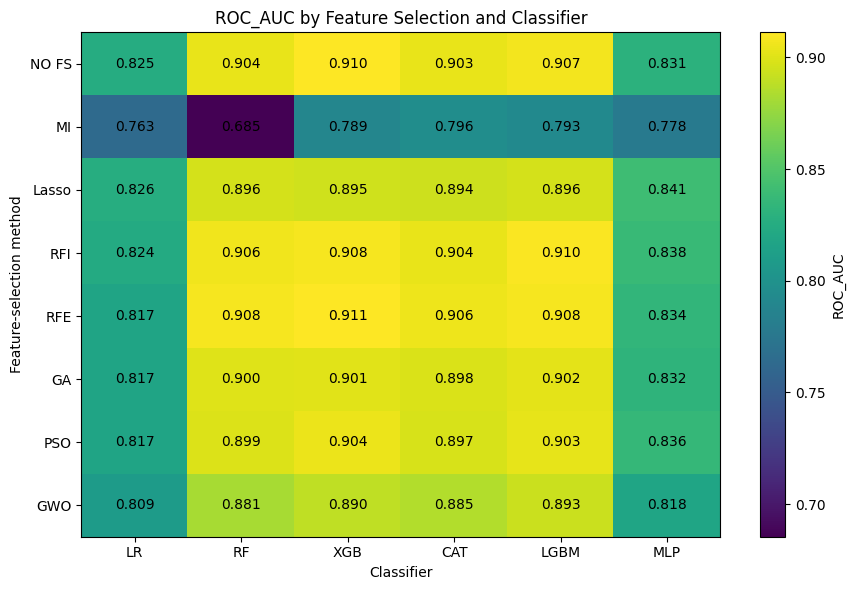

In [19]:
# 10. CHART 1: HEATMAP OF ALL COMBINATIONS
# ============================================================

heatmap_data = df.pivot(
    index="fs_method",
    columns="classifier",
    values=PRIMARY_METRIC
)

heatmap_data = heatmap_data.reindex(
    [
        method for method in FS_ORDER
        if method in heatmap_data.index
    ]
)

heatmap_data = heatmap_data[
    [
        model for model in CLASSIFIER_ORDER
        if model in heatmap_data.columns
    ]
]

fig, ax = plt.subplots(figsize=(9, 6))

image = ax.imshow(
    heatmap_data.values,
    aspect="auto"
)

ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(np.arange(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

ax.set_xlabel("Classifier")
ax.set_ylabel("Feature-selection method")
ax.set_title(
    f"{PRIMARY_METRIC} by Feature Selection and Classifier"
)

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        ax.text(
            j,
            i,
            f"{heatmap_data.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    image,
    ax=ax,
    label=PRIMARY_METRIC
)

plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        f"heatmap_{PRIMARY_METRIC}.png"
    ),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

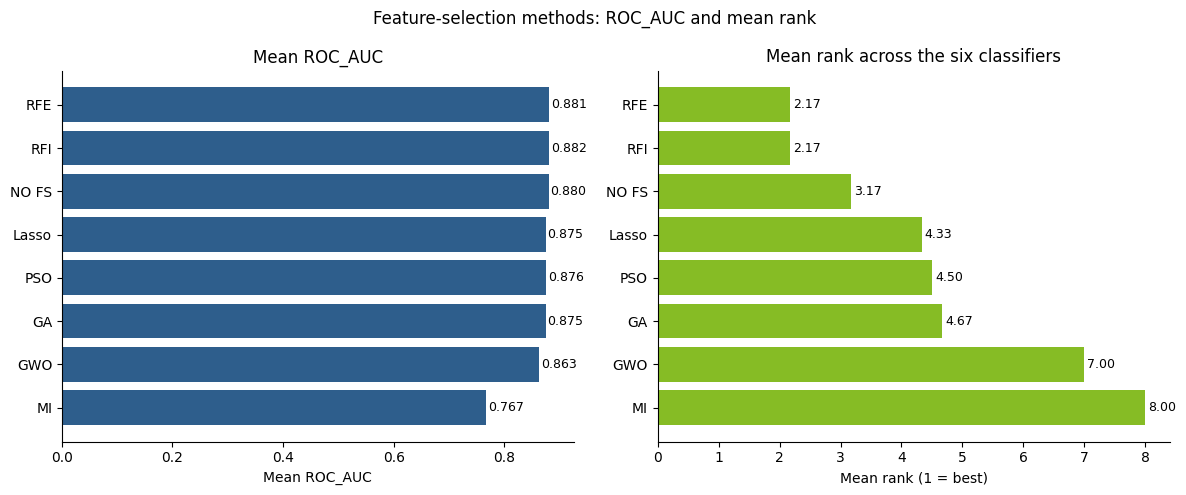

In [ ]:
plot_fs = fs_summary.sort_values("Mean_Rank", ascending=False)   # worst rank at top

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.barh(plot_fs.index, plot_fs["Mean"], color="#2E5E8C")
ax1.set_xlabel(f"Mean {PRIMARY_METRIC}")
ax1.set_title(f"Mean {PRIMARY_METRIC}")
for i, v in enumerate(plot_fs["Mean"]):
    ax1.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)

ax2.barh(plot_fs.index, plot_fs["Mean_Rank"], color="#86BC25")
ax2.set_xlabel("Mean rank (1 = best)")
ax2.set_title("Mean rank across the six classifiers")
for i, v in enumerate(plot_fs["Mean_Rank"]):
    ax2.text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=9)

for a in (ax1, ax2):
    a.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"Feature-selection methods: {PRIMARY_METRIC} and mean rank")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f"mean_fs_{PRIMARY_METRIC}.png"),
            dpi=300, bbox_inches="tight")
plt.show()

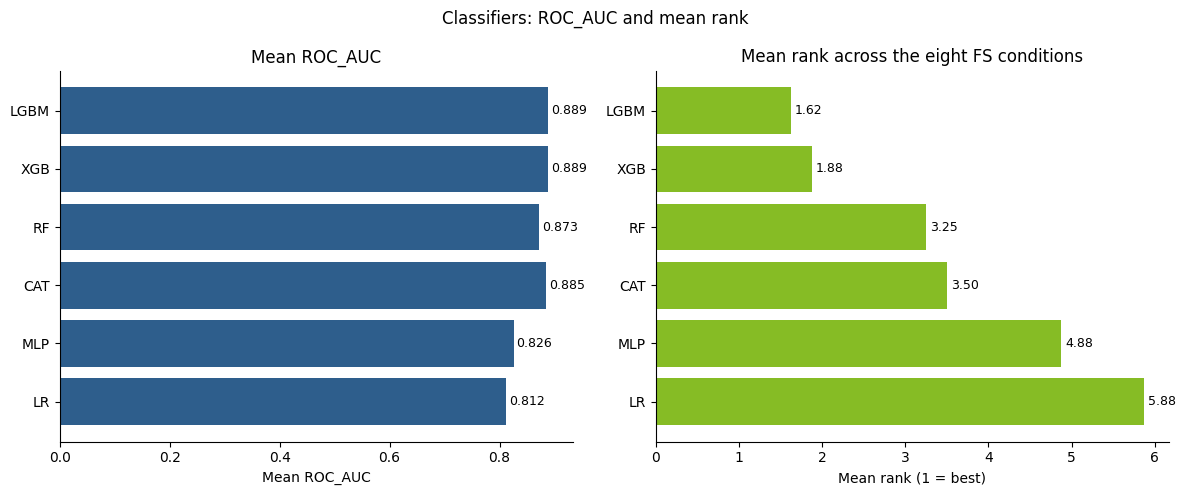

In [21]:
# 12. CHART 3: MEAN PERFORMANCE BY CLASSIFIER
# ============================================================

plot_clf = classifier_summary.sort_values("Mean_Rank", ascending=False)  # worst at top

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.barh(plot_clf.index, plot_clf["Mean"], color="#2E5E8C")
ax1.set_xlabel(f"Mean {PRIMARY_METRIC}")
ax1.set_title(f"Mean {PRIMARY_METRIC}")
for i, v in enumerate(plot_clf["Mean"]):
    ax1.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)

ax2.barh(plot_clf.index, plot_clf["Mean_Rank"], color="#86BC25")
ax2.set_xlabel("Mean rank (1 = best)")
ax2.set_title("Mean rank across the eight FS conditions")
for i, v in enumerate(plot_clf["Mean_Rank"]):
    ax2.text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=9)

for a in (ax1, ax2):
    a.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"Classifiers: {PRIMARY_METRIC} and mean rank")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f"mean_classifier_{PRIMARY_METRIC}.png"),
            dpi=300, bbox_inches="tight")
plt.show()

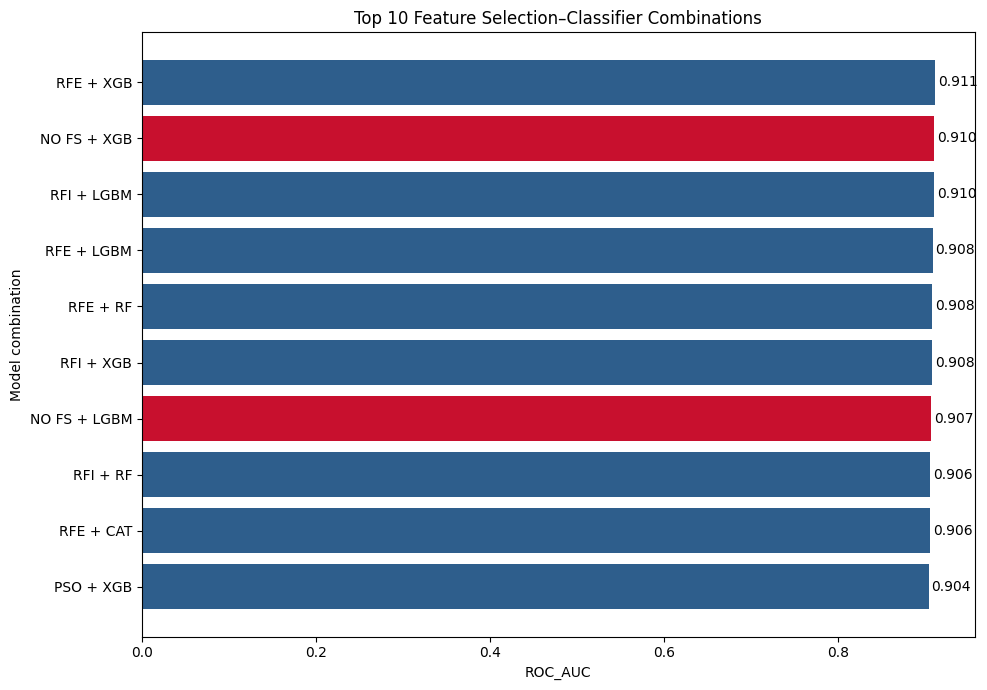

In [22]:
# 13. CHART 4: TOP COMBINATIONS
# ============================================================

top_n = 10

top_combinations = ranking.head(top_n).copy()

top_combinations["Combination"] = (
    top_combinations["fs_method"] + " + " + top_combinations["classifier"]
)

top_combinations = top_combinations.sort_values(PRIMARY_METRIC, ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))

# highlight the no-selection control
colors = ["#C8102E" if "NO FS" in c else "#2E5E8C"
          for c in top_combinations["Combination"]]

ax.barh(
    top_combinations["Combination"],
    top_combinations[PRIMARY_METRIC],
    color=colors
)

ax.set_xlabel(PRIMARY_METRIC)
ax.set_ylabel("Model combination")
ax.set_title(f"Top {top_n} Feature Selection–Classifier Combinations")

for i, value in enumerate(top_combinations[PRIMARY_METRIC]):
    ax.text(value + 0.003, i, f"{value:.3f}", va="center")

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, f"top_combinations_{PRIMARY_METRIC}.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [26]:
# OUTPUT LOCATION
# ============================================================

print(f"\nAll tables and figures were saved in: {os.path.abspath(OUTPUT_DIR)}")
print("\nFiles:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print("  ", f)


All tables and figures were saved in: c:\Users\admin\Desktop\M2 thesis\statistical_analysis

Files:
   classifier_matrix_PR_AUC.csv
   classifier_summary_PR_AUC.csv
   combination_ranking_PR_AUC.csv
   feature_selection_summary_PR_AUC.csv
   friedman_results_PR_AUC.csv
   fs_matrix_PR_AUC.csv
   heatmap_PR_AUC.png
   mean_classifier_PR_AUC.png
   mean_fs_PR_AUC.png
   shaffer_classifiers.csv
   shaffer_feature_selection.csv
   top_combinations_PR_AUC.png


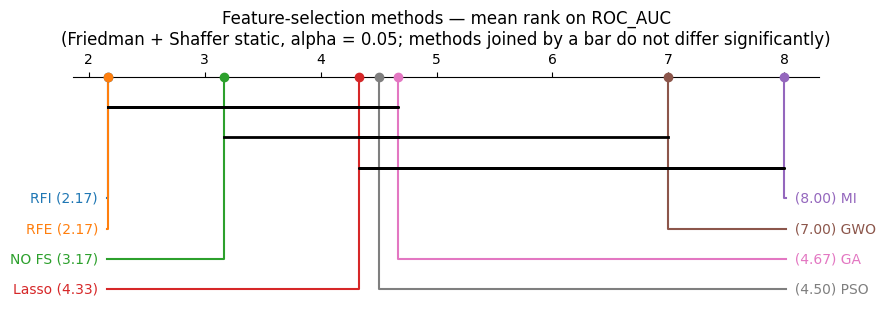

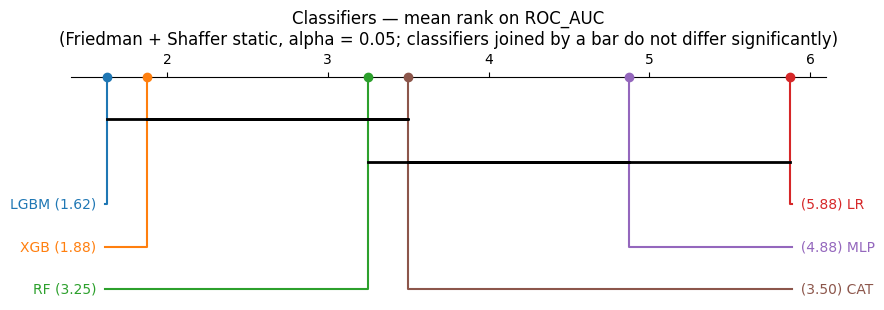

" Each method sits on a horizontal axis of mean rank,\nbest (lowest) on the left. A method's line drops to its label. The thick black\ncrossbars join methods whose difference was NOT significant after Shaffer\ncorrection — anything sharing a bar is statistically indistinguishable.\n\nHere, two overlapping bars cover NO FS through Lasso and RFE through GWO, so all\n28 pairs are non-significant except NO FS versus GWO — the only pair not sharing\na bar. With six blocks (one per classifier) the test has limited power, so the\nabsence of separation reflects both genuine similarity between the methods and\nthe small number of blocks. "

In [23]:
# 14. CRITICAL DIFFERENCE DIAGRAMS
# ============================================================
# Shaffer's adjusted alpha varies per comparison, so there is no single
# critical-difference constant. The diagram is drawn from the pairwise
# reject/retain decisions: methods joined by a bar are NOT significantly
# different after correction.

def shaffer_sig_matrix(res, names):
    """Square matrix for critical_difference_diagram: 0 = significant, 1 = not."""
    M = pd.DataFrame(1.0, index=names, columns=names)
    for _, r in res.iterrows():
        value = 0.0 if r["reject"] else 1.0
        M.loc[r["A"], r["B"]] = value
        M.loc[r["B"], r["A"]] = value
    np.fill_diagonal(M.values, 1.0)
    return M


def plot_cd(res, ranks, title, filename):
    if res is None:
        print(f"{title}: Friedman not significant — no CD diagram drawn.")
        return

    sig = shaffer_sig_matrix(res, list(ranks.index))

    fig, ax = plt.subplots(figsize=(9, 3.2))
    sp.critical_difference_diagram(
        ranks=ranks,
        sig_matrix=sig,
        ax=ax,
        label_fmt_left="{label} ({rank:.2f})  ",
        label_fmt_right="  ({rank:.2f}) {label}",
        crossbar_props={"linewidth": 2},
    )
    ax.set_title(title)


    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()


plot_cd(fs_shaffer, fs_ranks,
        f"Feature-selection methods — mean rank on {PRIMARY_METRIC}\n"
        f"(Friedman + Shaffer static, alpha = {ALPHA}; methods joined by a bar do not differ significantly)",
        f"cd_feature_selection_{PRIMARY_METRIC}.png")

plot_cd(clf_shaffer, clf_ranks,
        f"Classifiers — mean rank on {PRIMARY_METRIC}\n"
        f"(Friedman + Shaffer static, alpha = {ALPHA}; classifiers joined by a bar do not differ significantly)",
        f"cd_classifiers_{PRIMARY_METRIC}.png")


""" Each method sits on a horizontal axis of mean rank,
best (lowest) on the left. A method's line drops to its label. The thick black
crossbars join methods whose difference was NOT significant after Shaffer
correction — anything sharing a bar is statistically indistinguishable.

Here, two overlapping bars cover NO FS through Lasso and RFE through GWO, so all
28 pairs are non-significant except NO FS versus GWO — the only pair not sharing
a bar. With six blocks (one per classifier) the test has limited power, so the
absence of separation reflects both genuine similarity between the methods and
the small number of blocks. """

Loaded subsets:
  ga         120 features
  gwo        120 features
  lasso      120 features
  mi         120 features
  pso        120 features
  rfe        120 features
  rfi        120 features

Jaccard similarity (1.0 = identical subsets):
          ga    gwo  lasso     mi    pso    rfe    rfi
ga     1.000  0.188  0.182  0.143  0.159  0.212  0.218
gwo    0.188  1.000  0.154  0.159  0.154  0.159  0.182
lasso  0.182  0.154  1.000  0.171  0.218  0.277  0.244
mi     0.143  0.159  0.171  1.000  0.148  0.116  0.067
pso    0.159  0.154  0.218  0.148  1.000  0.188  0.200
rfe    0.212  0.159  0.277  0.116  0.188  1.000  0.491
rfi    0.218  0.182  0.244  0.067  0.200  0.491  1.000

Selected by ALL methods: 1
Selected by AT LEAST ONE: 377 of 433


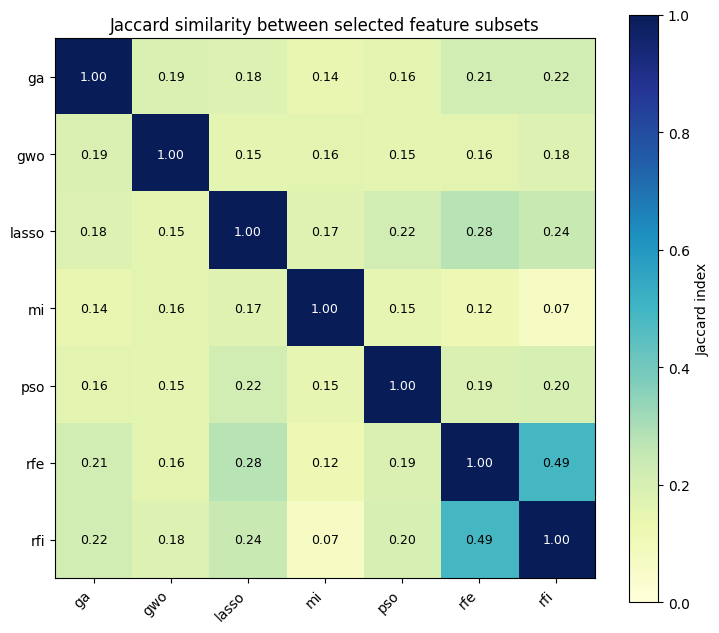

In [24]:
# 15. SUBSET OVERLAP BETWEEN FS METHODS (Jaccard)
# ============================================================
# Do the seven selection methods pick the SAME 120 features, or different ones?
# Low overlap combined with similar performance means many different subsets
# work equally well — evidence of heavy redundancy in the feature space.

import json, glob

subsets = {}
for path in glob.glob("FS_results/*selected_features.json"):
    name = os.path.basename(path).split("_selected")[0]
    with open(path) as fh:
        subsets[name] = set(json.load(fh))

print("Loaded subsets:")
for name, feats in sorted(subsets.items()):
    print(f"  {name:10s} {len(feats)} features")

names = sorted(subsets)
J = pd.DataFrame(
    [[len(subsets[a] & subsets[b]) / len(subsets[a] | subsets[b]) for b in names]
     for a in names],
    index=names, columns=names
)

print("\nJaccard similarity (1.0 = identical subsets):")
print(J.round(3).to_string())

J.round(4).to_csv(os.path.join(OUTPUT_DIR, "subset_jaccard.csv"))

# how many features every method agreed on, and how many any method picked
common = set.intersection(*subsets.values())
union  = set.union(*subsets.values())
print(f"\nSelected by ALL methods: {len(common)}")
print(f"Selected by AT LEAST ONE: {len(union)} of 433")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(J.values, vmin=0, vmax=1, cmap="YlGnBu")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{J.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if J.iloc[i, j] > 0.6 else "black", fontsize=9)
ax.set_title("Jaccard similarity between selected feature subsets")
fig.colorbar(im, ax=ax, label="Jaccard index")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "subset_jaccard.png"), dpi=300, bbox_inches="tight")
plt.show()


PARSIMONY: PERFORMANCE RETAINED VERSUS FEATURES USED
           Mean_Metric  Mean_Features  Mean_Train_Seconds  Pct_of_Full_Metric  Pct_of_Full_Features  Pct_of_Full_Train_Time
fs_method                                                                                                                  
RFI               0.88          120.0              125.59              100.16                 27.71                   50.67
RFE               0.88          120.0              124.42              100.08                 27.71                   50.20
NO FS             0.88          433.0              247.84              100.00                100.00                  100.00
PSO               0.88          120.0               78.28               99.54                 27.71                   31.59
GA                0.88          120.0               78.97               99.42                 27.71                   31.86
Lasso             0.87          120.0               41.96               99.40 

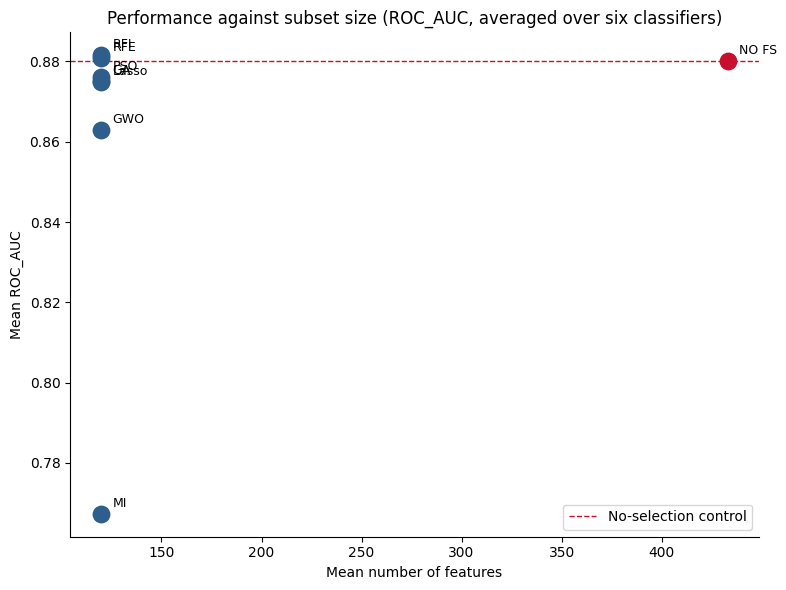

In [30]:
# 16. PARSIMONY ANALYSIS
# ============================================================
# What does the feature reduction cost in performance, and what does it buy
# in model size and training time? NO FS is the reference condition.

parsimony = (
    df.groupby("fs_method")
      .agg(Mean_Metric=(PRIMARY_METRIC, "mean"),
           Mean_Features=("Features", "mean"),
           Mean_Train_Seconds=("Training_Time_Seconds", "mean"))
)

ref = parsimony.loc["NO FS"]

parsimony["Pct_of_Full_Metric"]  = 100 * parsimony["Mean_Metric"]  / ref["Mean_Metric"]
parsimony["Pct_of_Full_Features"] = 100 * parsimony["Mean_Features"] / ref["Mean_Features"]
parsimony["Pct_of_Full_Train_Time"] = 100 * parsimony["Mean_Train_Seconds"] / ref["Mean_Train_Seconds"]

parsimony = parsimony.sort_values("Mean_Metric", ascending=False)

print("\n" + "=" * 70)
print("PARSIMONY: PERFORMANCE RETAINED VERSUS FEATURES USED")
print("=" * 70)
print(parsimony.round(2).to_string())

parsimony.round(4).to_csv(os.path.join(OUTPUT_DIR, "parsimony_analysis.csv"))

# ---- scatter: cost against benefit -------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

for name, row in parsimony.iterrows():
    is_ref = (name == "NO FS")
    ax.scatter(row["Mean_Features"], row["Mean_Metric"],
               s=140, color="#C8102E" if is_ref else "#2E5E8C", zorder=3)
    ax.annotate(name,
                (row["Mean_Features"], row["Mean_Metric"]),
                textcoords="offset points", xytext=(8, 5), fontsize=9)

ax.axhline(ref["Mean_Metric"], color="#C8102E", linestyle="--", linewidth=1,
           label="No-selection control")
ax.set_xlabel("Mean number of features")
ax.set_ylabel(f"Mean {PRIMARY_METRIC}")
ax.set_title(f"Performance against subset size ({PRIMARY_METRIC}, averaged over six classifiers)")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f"parsimony_{PRIMARY_METRIC}.png"),
            dpi=300, bbox_inches="tight")
plt.show()

In [30]:
# 17. OUTPUT LISTING
# ============================================================

print(f"\nAll tables and figures were saved in: {os.path.abspath(OUTPUT_DIR)}")

files = sorted(os.listdir(OUTPUT_DIR))
csvs = [f for f in files if f.endswith(".csv")]
pngs = [f for f in files if f.endswith(".png")]

print(f"\nTables ({len(csvs)}):")
for f in csvs:
    print("  ", f)

print(f"\nFigures ({len(pngs)}):")
for f in pngs:
    print("  ", f)


All tables and figures were saved in: c:\Users\admin\Desktop\M2 thesis\statistical_analysis

Tables (10):
   classifier_matrix_PR_AUC.csv
   classifier_summary_PR_AUC.csv
   combination_ranking_PR_AUC.csv
   feature_selection_summary_PR_AUC.csv
   friedman_results_PR_AUC.csv
   fs_matrix_PR_AUC.csv
   parsimony_analysis.csv
   shaffer_classifiers.csv
   shaffer_feature_selection.csv
   subset_jaccard.csv

Figures (8):
   cd_classifiers_PR_AUC.png
   cd_feature_selection_PR_AUC.png
   heatmap_PR_AUC.png
   mean_classifier_PR_AUC.png
   mean_fs_PR_AUC.png
   parsimony_PR_AUC.png
   subset_jaccard.png
   top_combinations_PR_AUC.png


In [ ]:
import matplotlib.pyplot as plt

# GA: full recorded generation history
plt.plot(ga_generation, ga_auc, label="GA")

# PSO and GWO: recorded convergence points
plt.plot(pso_iteration, pso_auc, marker="o", label="PSO")
plt.plot(gwo_iteration, gwo_auc, marker="o", label="GWO")

plt.xlabel("Iteration / recorded generation")
plt.ylabel("Best internal validation ROC-AUC")
plt.title("Recorded GA, PSO and GWO search trajectories")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

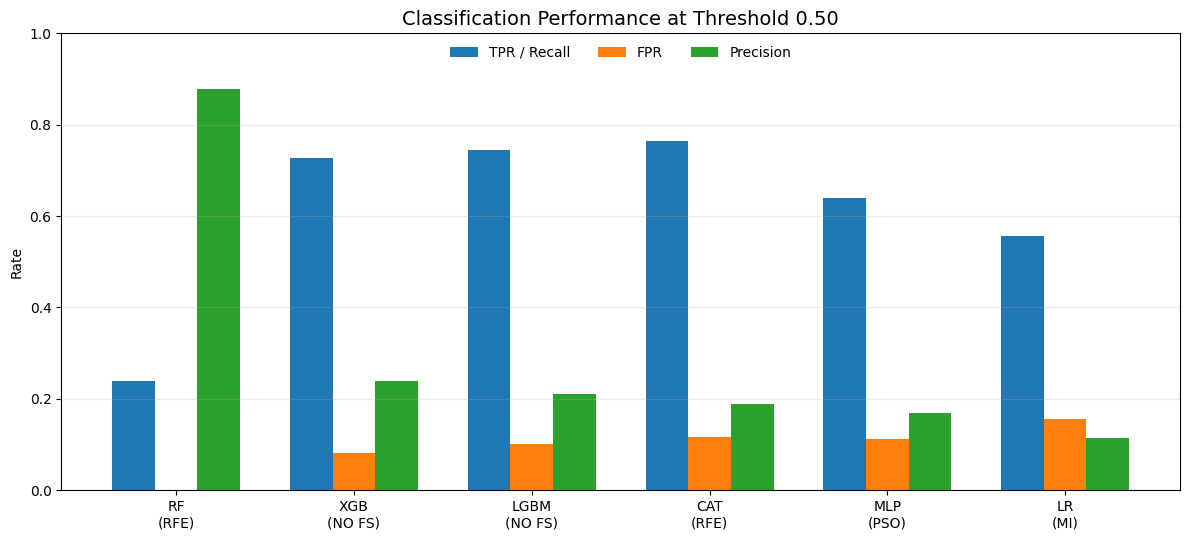

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Best PR-AUC configuration for each classifier
classifiers = [
    "RF\n(RFE)",
    "XGB\n(NO FS)",
    "LGBM\n(NO FS)",
    "CAT\n(RFE)",
    "MLP\n(PSO)",
    "LR\n(MI)"
]

# Threshold = 0.50
tpr = [0.2397, 0.7264, 0.7453, 0.7633, 0.6388, 0.5571]
fpr = [0.0012, 0.0820, 0.1003, 0.1171, 0.1127, 0.1559]
precision = [0.8791, 0.2399, 0.2094, 0.1884, 0.1680, 0.1130]

x = np.arange(len(classifiers))
width = 0.24

plt.figure(figsize=(12, 5.5))

plt.bar(x - width, tpr, width, label="TPR / Recall")
plt.bar(x, fpr, width, label="FPR")
plt.bar(x + width, precision, width, label="Precision")

plt.title("Classification Performance at Threshold 0.50", fontsize=14)
plt.ylabel("Rate")
plt.xlabel("")

plt.xticks(x, classifiers)
plt.ylim(0, 1.0)

plt.grid(axis="y", alpha=0.25)

plt.legend(
    loc="upper center",
    ncol=3,
    frameon=False
)

plt.tight_layout()

# Save high-quality image for thesis
plt.savefig(
    "classification_performance_threshold_050.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------
# -------------------------------------------------------------------------------------------------------------------------

In [ ]:
#----------------------------------------------------------------------------------------------------------------------------
#----------------------------------------------------------------------------------------------------------------------------
#----------------------------------------------------------------------------------------------------------------------------
#----------------------------------------------------------------------------------------------------------------------------

In [ ]:
# the next codes for NEMENYI I will replace by shaffer
# Nemenyi is conservative and Shaffer is more powerful for all-pairs comparisons (García & Herrera 2008)
from itertools import combinations
from scipy.stats import norm, rankdata

def _S(k):
    """Possible numbers of true null hypotheses among k treatments."""
    if k <= 1: return {0}
    out = set()
    for j in range(1, k + 1):
        out |= {j * (j - 1) // 2 + s for s in _S(k - j)}
    return out

def shaffer_static(matrix, alpha=0.05):
    """matrix: blocks x treatments. Returns per-pair p, adjusted alpha, reject."""
    names = list(matrix.columns)
    k, n = len(names), len(matrix)
    ranks = np.array([rankdata(-row) for row in matrix.values])   # 1 = best
    R = ranks.mean(axis=0)
    se = np.sqrt(k * (k + 1) / (6.0 * n))

    rows = []
    for i, j in combinations(range(k), 2):
        z = abs(R[i] - R[j]) / se
        rows.append({"A": names[i], "B": names[j],
                     "rank_A": R[i], "rank_B": R[j],
                     "z": z, "p": 2 * (1 - norm.cdf(z))})

    res = pd.DataFrame(rows).sort_values("p").reset_index(drop=True)
    m = len(res)
    S = sorted(_S(k))
    res["t_i"] = [max(x for x in S if x <= m - i) for i in range(m)]
    res["alpha_adj"] = alpha / res["t_i"]

    reject, still = [], True                    # step-down: stop at first failure
    for _, r in res.iterrows():
        still = still and (r["p"] <= r["alpha_adj"])
        reject.append(still)
    res["reject"] = reject
    return res, pd.Series(R, index=names).sort_values()

In [ ]:
sig = pd.DataFrame(1.0, index=names, columns=names)
for _, r in res.iterrows():
    sig.loc[r.A, r.B] = sig.loc[r.B, r.A] = 0.0 if r.reject else 1.0
sp.critical_difference_diagram(mean_ranks, sig)

In [31]:
from pathlib import Path
ROOT = Path(r"C:\\Users\\admin\\Desktop\\M2 thesis\\FS_Results")   # set this

for p in sorted(ROOT.rglob("*")):
    n = p.name.lower()
    if p.is_file() and ("histor" in n or "convergence" in n or "generation" in n
                        or (n.startswith("ga") and p.suffix in {".csv", ".json", ".txt", ".log"})):
        print(p, "|", p.stat().st_size, "bytes")

C:\Users\admin\Desktop\M2 thesis\FS_Results\GA_results.json | 2878 bytes
C:\Users\admin\Desktop\M2 thesis\FS_Results\ga_selected_features.json | 1552 bytes
C:\Users\admin\Desktop\M2 thesis\FS_Results\gwo_history.csv | 4227 bytes
C:\Users\admin\Desktop\M2 thesis\FS_Results\pso_history.csv | 4249 bytes


In [33]:
src = Path("C:/Users/admin/Desktop/M2 thesis/GA.py").read_text(encoding="utf-8", errors="replace")
for i, line in enumerate(src.splitlines(), 1):
    if any(k in line for k in ("to_csv", "history", "append", "print(", "json.dump")):
        print(f"{i:4d}| {line.rstrip()}")

  27| print(f"Merged shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
  38| print(f"{len(num_cols)} numeric  +  {len(cat_cols)} categorical  =  {len(num_cols)+len(cat_cols)} predictors")
  45| print(f"Train: {train.shape[0]:,} rows  (fraud {train['isFraud'].mean():.2%})")
  46| print(f"Test : {test.shape[0]:,} rows  (fraud {test['isFraud'].mean():.2%})")
 149|         population.append(ind)
 219|     print(f"Generation {gen} | Best AUC: {best_score:.5f}")
 236|         new_population.append(c1)
 238|             new_population.append(c2)
 246| print("Best AUC:", best_score)
 247| print("Selected features:", len(selected_features))
 248| print(selected_features)
 254| print("Best AUC:", best_score)
 255| print("Selected features:", len(selected_feature_names))
 256| print(selected_feature_names)
 262|     json.dump(selected_features, f, indent=4)
 264| print("Feature list saved!")
 269| print(f"Runtime: {runtime/60:.2f} minutes")
 307|     json.dump(results,f,indent=4)


In [35]:
import json
for nb in ROOT.rglob("*.ipynb"):
    if ".ipynb_checkpoints" in str(nb):
        continue
    text = json.dumps(json.loads(nb.read_text(encoding="utf-8", errors="replace")))
    if "Generation" in text or "generation" in text:
        print(nb)

In [ ]:
history = []          # before the generation loop

# inside the loop, next to the existing print
history.append({
    "generation": gen,
    "best_auc_generation": best_score,
    "mean_auc_generation": float(np.mean(fitness_scores)),
    "global_best_auc": global_best,
    "global_best_features": int(global_best_mask.sum()),
    "runtime_minutes": (time.time() - start) / 60,
})

# after the loop
pd.DataFrame(history).to_csv(ROOT/ "ga_history.csv", index=False)